# QuietTracE — experiments

Notebook para iterar sobre el modelo y el QAOA **fuera de Qollab**, con vuestro
entorno Python. Reutiliza los módulos del repo:

- `quantum/modelo.py`   — modelo (rutas, conflictos, pesos geométricos, Ising, exacto)
- `quantum/fastqaoa.py` — QAOA exacto y rápido (NumPy)
- `quantum/qaoa.py`     — circuito QAOA para backend (ángulos numéricos, sin parámetros libres)
- `quantum/pipeline.py` — orquestación (problem, distribución, mejor solución)

Ejecutad las celdas en orden y ajustad parámetros en cada sección.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))  # raíz del repo (notebook en notebooks/)

import numpy as np
import matplotlib.pyplot as plt

from quantum import modelo as M
from quantum import fastqaoa, qaoa, pipeline

np.set_printoptions(precision=4, suppress=True)
print("numpy", np.__version__)

numpy 2.5.3


## 1. Problema: variables y restricciones (antes de optimizar)

In [2]:
prob = pipeline._problem()
nets = prob["nets"]; n = len(nets)

print("redes:", nets)
print("conflictos (restricciones):")
for i, j in sorted(prob["conflicts"]):
    print("  ", nets[i], "-", nets[j])
print("vías por red (L4):", float(prob["vias"][0]), "| lambda_v:", prob["lam_v"])
print("M (penalización de conflicto):", round(prob["M"], 4))
print("h (campos Ising):", np.round(prob["h"], 3))

redes: ['D0', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'CLK']
conflictos (restricciones):
   D0 - D2
   D0 - D4
   D1 - D2
   D1 - D4
   D3 - D4
   D6 - D7
vías por red (L4): 2.0 | lambda_v: 0.5
M (penalización de conflicto): 8.0492
h (campos Ising): [-0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5 -0.5]


## 2. Óptimo exacto (referencia, 2^n)

In [3]:
exact_cost, exact_bits = M.solve_exact(prob["W"], prob["vias"], prob["lam_v"], prob["conflicts"], prob["M"])
exact_bits = [int(b) for b in exact_bits]
print("costo óptimo:", round(exact_cost, 5), "| bits:", exact_bits)
print("L1:", [nets[i] for i,b in enumerate(exact_bits) if b==0])
print("L4:", [nets[i] for i,b in enumerate(exact_bits) if b==1])

costo óptimo: 7.04918 | bits: [0, 0, 1, 0, 1, 0, 0, 1, 0]
L1: ['D0', 'D1', 'D3', 'D5', 'D6', 'CLK']
L4: ['D2', 'D4', 'D7']


## 3. QAOA: optimización y convergencia

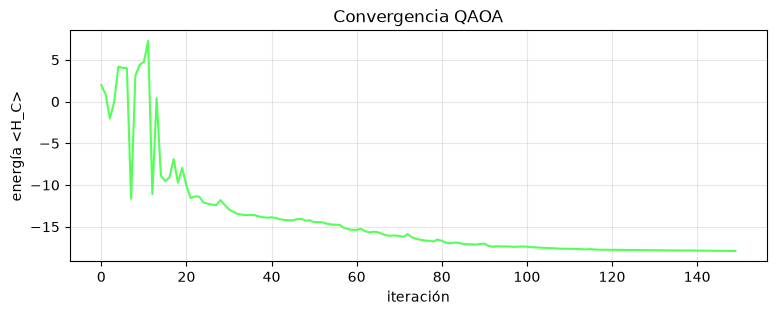

energía final: -17.905 | parámetros: 6


In [4]:
REPS, MAXITER = 3, 150
qa = fastqaoa.run_qaoa(prob["J"], prob["h"], reps=REPS, maxiter=MAXITER)

plt.figure(figsize=(9,3))
plt.plot(qa["history"], color="#54ff57")
plt.xlabel("iteración"); plt.ylabel("energía <H_C>")
plt.title("Convergencia QAOA"); plt.grid(True, alpha=.3); plt.show()
print("energía final:", round(qa["energy"], 4), "| parámetros:", qa["num_parameters"])

## 4. Solución QAOA + distribución

In [5]:
X, total, ising, feasible = pipeline._vector_metrics(prob, n)
rank = np.argsort(qa["probabilities"])[::-1][:64]
dist = [{"x": [int(b) for b in X[k]], "prob": float(qa["probabilities"][k]),
         "cost": float(total[k]), "feasible": bool(feasible[k])} for k in rank]
best = pipeline._best_feasible(dist)


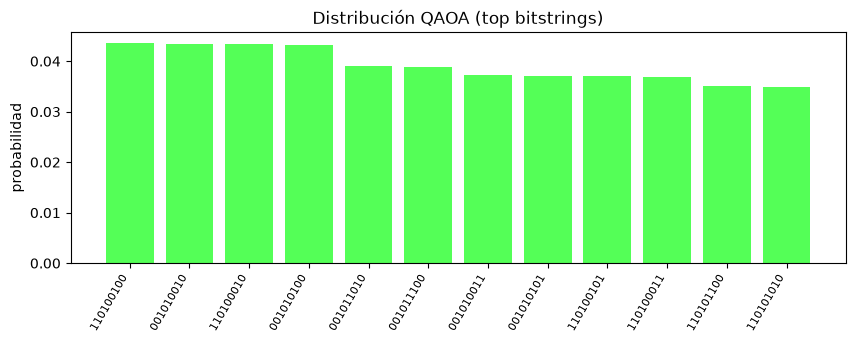

In [6]:
top = dist[:12]
labels = ["".join(map(str, d["x"])) for d in top]
colors = ["#54ff57" if d["feasible"] else "#ff6b6b" for d in top]
plt.figure(figsize=(10,3))
plt.bar(range(len(top)), [d["prob"] for d in top], color=colors)
plt.xticks(range(len(top)), labels, rotation=60, ha="right", fontsize=8)
plt.ylabel("probabilidad"); plt.title("Distribución QAOA (top bitstrings)"); plt.show()

## 5. Circuito QAOA (ángulos numéricos) + muestreo local

parámetros libres: 0 | profundidad: 41
puertas: {'rzz': 108, 'rz': 27, 'rx': 27, 'h': 9, 'measure': 9, 'barrier': 1}


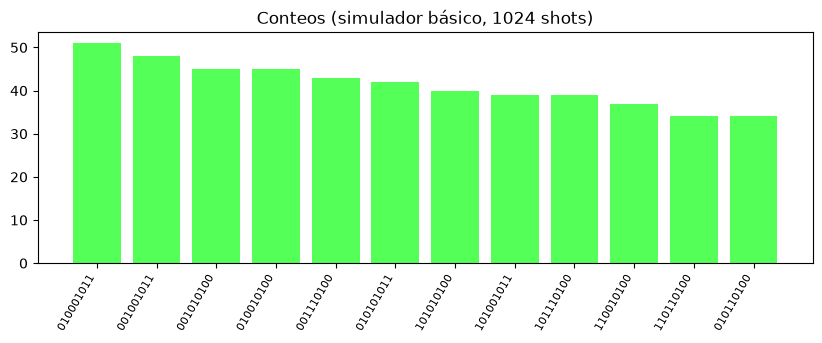

In [7]:
circ = qaoa.build_circuit(prob["J"], prob["h"], REPS, qa["theta"])
print("parámetros libres:", len(circ.parameters), "| profundidad:", circ.depth())
print("puertas:", dict(circ.count_ops()))

from qiskit.providers.basic_provider import BasicSimulator
counts = BasicSimulator().run(circ, shots=1024).result().get_counts()
topc = sorted(counts.items(), key=lambda kv: -kv[1])[:12]
plt.figure(figsize=(10,3))
plt.bar(range(len(topc)), [c for _,c in topc], color="#54ff57")
plt.xticks(range(len(topc)), [k for k,_ in topc], rotation=60, ha="right", fontsize=8)
plt.title("Conteos (simulador básico, 1024 shots)"); plt.show()

## 6. Simulador con ruido (opcional, requiere qiskit-aer)

In [8]:
try:
    from qiskit_aer import AerSimulator
    from qiskit_aer.noise import NoiseModel, depolarizing_error
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.01, 2), ["rzz"])
    nm.add_all_qubit_quantum_error(depolarizing_error(0.005, 1), ["rz", "rx", "h"])
    sim = AerSimulator(noise_model=nm)
    rc = sim.run(circ, shots=1024).result().get_counts()
    print("top con ruido:", sorted(rc.items(), key=lambda kv:-kv[1])[:6])
except Exception as e:
    print("qiskit-aer no disponible:", e)

qiskit-aer no disponible: No module named 'qiskit_aer'


## 7. IonQ (opcional, requiere qiskit-ionq y IONQ_API_KEY)

In [9]:
import os
try:
    from qiskit_ionq import IonQProvider
    token = os.environ.get("IONQ_API_KEY")
    assert token, "exporta IONQ_API_KEY antes de correr esta celda"
    backend = IonQProvider(token).get_backend("ionq_forte")  # o un simulador IonQ
    # NO transpilar para IonQ: enviar el circuito como está (ángulos numéricos válidos)
    job = backend.run(circ, shots=1024)
    print("job:", job.job_id())
    print("counts:", sorted(job.result().get_counts().items(), key=lambda kv:-kv[1])[:8])
except Exception as e:
    print("IonQ no disponible:", e)

IonQ no disponible: No module named 'qiskit_ionq'


## 8. Barridos de parámetros

In [10]:
X, total, ising, feasible = pipeline._vector_metrics(prob, n)
rank = np.argsort(qa["probabilities"])[::-1][:64]
dist = [{"x": [int(b) for b in X[k]], "prob": float(qa["probabilities"][k]),
         "cost": float(total[k]), "feasible": bool(feasible[k])} for k in rank]
best = pipeline._best_feasible(dist)


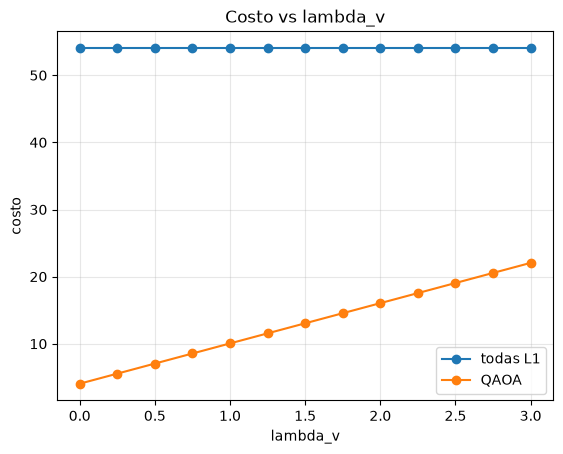

In [11]:
# lambda_v (costo por vía)
lams = np.linspace(0, 3, 13)
for name, bits in [("todas L1", [0]*n), ("QAOA", best["x"])]:
    vals = [M.full_cost(bits, prob["W"], prob["vias"], lv, prob["conflicts"], prob["M"]) for lv in lams]
    plt.plot(lams, vals, "o-", label=name)
plt.xlabel("lambda_v"); plt.ylabel("costo"); plt.title("Costo vs lambda_v")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

## 9. Pesos capacitivos COMSOL (datos reales)

La heurística geométrica original se puede sustituir por el acoplamiento capacitivo mutuo
`C'_m(s)` medido con COMSOL 6.1 (`quantum/comsol_capacitance.csv`, 11 puntos entre 0.2 y 4 mm).
El peso entre pistas es

$$w_{ij} = \frac{1}{C_\mathrm{ref}} \int_0^L C'_m(s_{ij}(x))\,dx$$

interpolando `C'_m` en escala log-log y **extrapolando la cola con una ley de potencia**
(ajuste a los 3 últimos puntos) por encima de 4 mm. Aquí se valida la curva, la extrapolación
y el efecto sobre la solución. La implementación vive en `quantum/capacitance.py`; el visor lo
conmuta con el botón **Weights: Geometric / COMSOL**.


puntos COMSOL: 11 | rango (0.2, 4.0) mm
pendiente de la cola (ley de potencia): -1.472


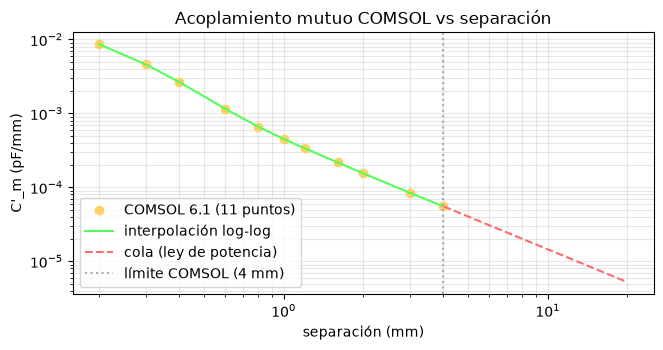

In [12]:
from quantum import capacitance as C, problem2

gap, cm = C.load_comsol_curve()
print("puntos COMSOL:", len(gap), "| rango", (float(gap.min()), float(gap.max())), "mm")
slope = np.polyfit(np.log(gap[-3:]), np.log(cm[-3:]), 1)[0]
print("pendiente de la cola (ley de potencia):", round(float(slope), 3))

gx = np.logspace(np.log10(gap.min()), np.log10(20.0), 300)
inside = gx <= gap.max()
plt.figure(figsize=(7.5, 3.4))
plt.loglog(gap, cm, "o", color="#ffd166", label="COMSOL 6.1 (11 puntos)")
plt.loglog(gx[inside], C.capacitance_per_mm(gx[inside]), "-", color="#54ff57", label="interpolación log-log")
plt.loglog(gx[~inside], C.capacitance_per_mm(gx[~inside]), "--", color="#ff6b6b", label="cola (ley de potencia)")
plt.axvline(gap.max(), color="#a8a8b4", ls=":", label="límite COMSOL (4 mm)")
plt.xlabel("separación (mm)"); plt.ylabel("C'_m (pF/mm)")
plt.title("Acoplamiento mutuo COMSOL vs separación")
plt.legend(); plt.grid(True, which="both", alpha=.3); plt.show()


1 ADC (9 pistas): max  geom 1.0000 / comsol 0.0429 | suma geom 5.8117 / comsol 0.2670
2 ADC (18 pistas): max  geom 0.4667 / comsol 0.0201 | suma geom 10.7951 / comsol 0.5272


/tmp/ipykernel_47391/2520837860.py:5: UserWarning: Gap reaches 9.20 mm; COMSOL data ends at 4.00 mm. Tail is power-law extrapolation, not simulated.
  return C.mutual_capacitance_weights(list(nets), routes, conflicts)
/tmp/ipykernel_47391/2520837860.py:5: UserWarning: Gap reaches 20.00 mm; COMSOL data ends at 4.00 mm. Tail is power-law extrapolation, not simulated.
  return C.mutual_capacitance_weights(list(nets), routes, conflicts)


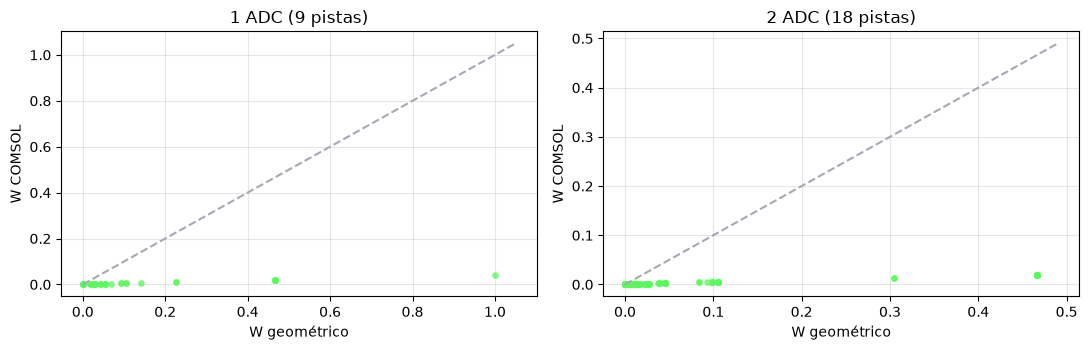

In [13]:
def weights_for(nets, order, source):
    routes = M.make_routes(list(nets), list(order))
    conflicts = M.find_conflicts(list(nets), routes)
    if source == "comsol":
        return C.mutual_capacitance_weights(list(nets), routes, conflicts)
    return M.geometric_weights(list(nets), routes, conflicts)

cases = [("1 ADC (9 pistas)", list(M.NETS), list(M.RIGHT_ORDER)),
         ("2 ADC (18 pistas)", list(problem2.NETS_2ADC), list(problem2.OUT_ORDER))]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, (label, nets, order) in zip(axes, cases):
    Wg, Wc = weights_for(nets, order, "geom"), weights_for(nets, order, "comsol")
    iu = np.triu_indices(len(nets), 1)
    print(f"{label}: max  geom {Wg[iu].max():.4f} / comsol {Wc[iu].max():.4f} | "
          f"suma geom {Wg[iu].sum():.4f} / comsol {Wc[iu].sum():.4f}")
    ax.scatter(Wg[iu], Wc[iu], s=14, color="#54ff57", alpha=.7)
    lim = max(float(Wg[iu].max()), float(Wc[iu].max())) * 1.05
    ax.plot([0, lim], [0, lim], ls="--", color="#a8a8b4")
    ax.set_title(label); ax.set_xlabel("W geométrico"); ax.set_ylabel("W COMSOL"); ax.grid(True, alpha=.3)
plt.tight_layout(); plt.show()


In [14]:
# El MISMO QAOA, con los dos juegos de pesos: ¿cambia la asignación de capas?
for kind, label in [("1adc", "1 ADC"), ("2adc", "2 ADC")]:
    mg = pipeline.get_model(kind, None, None, "geom")
    mc = pipeline.get_model(kind, None, None, "comsol")
    same = mg["assignments"]["after"] == mc["assignments"]["after"]
    print(f"{label}:  geom cost {mg['costs']['after']['total']:.4f} "
          f"(exacto {mg['exact']['cost']})  |  comsol cost {mc['costs']['after']['total']:.4f} "
          f"(exacto {mc['exact']['cost']})  |  misma asignación: {same}")
    print("   geom   L4:", mg["assignments"]["after_layers"]["L4"])
    print("   comsol L4:", mc["assignments"]["after_layers"]["L4"])


/mnt/ubuntu/home/anotherdev/workspace/personal/QuietTracE/quantum/pipeline.py:58: UserWarning: Gap reaches 9.20 mm; COMSOL data ends at 4.00 mm. Tail is power-law extrapolation, not simulated.
  W = capacitance.mutual_capacitance_weights(nets, routes, conflicts)


1 ADC:  geom cost 7.0492 (exacto 7.049177)  |  comsol cost 3.1837 (exacto 3.183721)  |  misma asignación: True
   geom   L4: ['D2', 'D4', 'D7']
   comsol L4: ['D2', 'D4', 'D7']


/mnt/ubuntu/home/anotherdev/workspace/personal/QuietTracE/quantum/pipeline.py:58: UserWarning: Gap reaches 20.00 mm; COMSOL data ends at 4.00 mm. Tail is power-law extrapolation, not simulated.
  W = capacitance.mutual_capacitance_weights(nets, routes, conflicts)


2 ADC:  geom cost 224.2072 (exacto None)  |  comsol cost 113.6448 (exacto None)  |  misma asignación: False
   geom   L4: ['D5', 'D8', 'D9', 'D10', 'D12', 'D14', 'CLK2']
   comsol L4: ['D1', 'D5', 'D8', 'D9', 'D10', 'D11', 'D12', 'D14', 'CLK2']


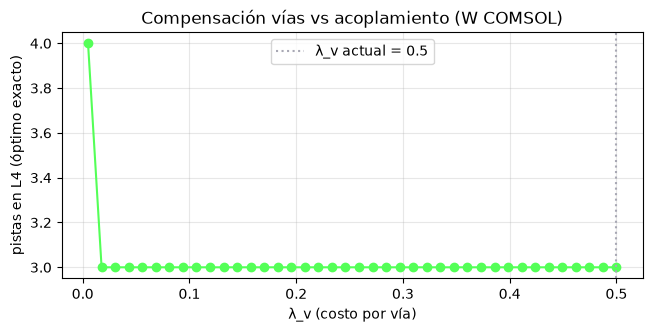

pesos COMSOL: max 0.0429 | mediana (no nulos) 0.00444 | costo de 1 vía (λ_v·v): 1.0


In [15]:
# Compensación vías (~1.0) vs acoplamiento (<0.05): cuántas pistas bajan a L4 según lambda_v
pc = pipeline._problem("1adc", None, "comsol")
lams = np.linspace(0.005, 0.5, 40)
n_l4 = []
for lv in lams:
    _, bits = M.solve_exact(pc["W"], pc["vias"], lv, pc["conflicts"], pc["M"])
    n_l4.append(int(np.sum(bits)))
plt.figure(figsize=(7.5, 3.2))
plt.plot(lams, n_l4, "o-", color="#54ff57")
plt.axvline(pc["lam_v"], color="#a8a8b4", ls=":", label=f"λ_v actual = {pc['lam_v']}")
plt.xlabel("λ_v (costo por vía)"); plt.ylabel("pistas en L4 (óptimo exacto)")
plt.title("Compensación vías vs acoplamiento (W COMSOL)")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

iu = np.triu_indices(len(M.NETS), 1)
nz = pc["W"][iu][pc["W"][iu] > 0]
print("pesos COMSOL: max", round(float(pc["W"][iu].max()), 4),
      "| mediana (no nulos)", round(float(np.median(nz)), 5),
      "| costo de 1 vía (λ_v·v):", pc["lam_v"] * float(pc["vias"][0]))


**Lectura.** Con `C_ref = 1 pF` los pesos capacitivos (≲0.05) son mucho menores que el
costo de una vía (`λ_v·v = 1.0`), así que el óptimo baja a L4 solo lo justo para resolver
conflictos; el barrido de `λ_v` muestra cuántas pistas bajan según se pondere el compromiso.
La cola por encima de 4 mm es una **extrapolación**, no una medición de COMSOL: conviene
extender la simulación o fijar y documentar un umbral de acoplamiento despreciable.


## 10. Barrido de profundidad p y peso de conflicto (18 qubits)

A 18 qubits solo **2 de 262 144** estados son factibles, asi que la masa factible del QAOA es
el cuello de botella. Aqui se barre la **profundidad `p`** y el **peso de conflicto** (`cmult`,
el `M` de la UI) para ver que hace falta para que el circuito **produzca** soluciones factibles.

Conclusion medida: **subir `p` solo no basta** (a `x1` el resultado es erratico). El interruptor
real es el **peso de conflicto**: con `x5`, `p >= 3` da ~20 muestras validas por 3072 shots
(`p = 5` ligeramente el mejor). A 9 qubits, en cambio, `x1` es mejor (ver seccion 9).


18 qubits: M0 = 19.228 | estados factibles = 2 / 262144


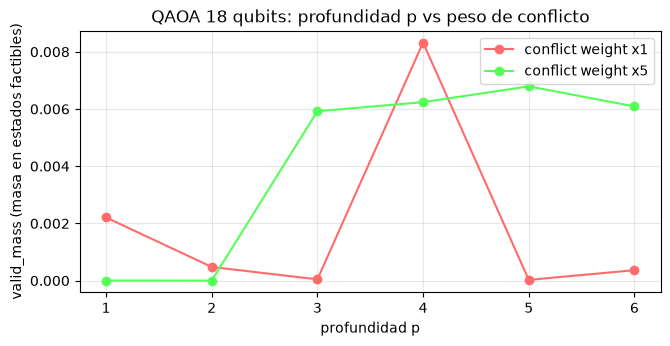

x1: p=1: 0.0022 (~7 validos/3072) | p=2: 0.0005 (~1 validos/3072) | p=3: 0.0000 (~0 validos/3072) | p=4: 0.0083 (~26 validos/3072) | p=5: 0.0000 (~0 validos/3072) | p=6: 0.0004 (~1 validos/3072)
x5: p=1: 0.0000 (~0 validos/3072) | p=2: 0.0000 (~0 validos/3072) | p=3: 0.0059 (~18 validos/3072) | p=4: 0.0062 (~19 validos/3072) | p=5: 0.0068 (~21 validos/3072) | p=6: 0.0061 (~19 validos/3072)


In [16]:
from quantum import modelo as M, fastqaoa as fq, problem2

nets = list(problem2.NETS_2ADC); order = list(problem2.OUT_ORDER)
routes = M.make_routes(nets, order); conflicts = M.find_conflicts(nets, routes)
W = M.geometric_weights(nets, routes, conflicts)
vias = np.full(len(nets), 2.0); lam = 0.5
feas = M.conflict_coloring(len(nets), conflicts)
upper = M.soft_cost(feas, W, vias, lam)
M0 = upper + max(1.0, 0.05 * upper)
n = len(nets)
X = ((np.arange(1 << n)[:, None] >> np.arange(n)) & 1).astype(np.int8)
viol = np.zeros(1 << n, dtype=np.int32)
for (i, j) in conflicts:
    viol += (X[:, i] == X[:, j]).astype(np.int32)
mask = viol == 0
print(f"18 qubits: M0 = {M0:.3f} | estados factibles = {int(mask.sum())} / {1 << n}")

ps = [1, 2, 3, 4, 5, 6]
tabla = {}
for c in (1.0, 5.0):
    fila = []
    for p in ps:
        Q, cQ, J, h, cI = M.build_model(W, vias, lam, conflicts, M=M0 * c)
        qa = fq.run_qaoa(J, h, reps=p, maxiter=150)
        P = np.asarray(qa["probabilities"], float)
        fila.append((float(P[mask].sum()), float(P[mask].max())))
    tabla[c] = fila

plt.figure(figsize=(7.5, 3.4))
for c, col in [(1.0, "#ff6b6b"), (5.0, "#54ff57")]:
    plt.plot(ps, [f[0] for f in tabla[c]], "o-", color=col, label=f"conflict weight x{c:g}")
plt.xlabel("profundidad p"); plt.ylabel("valid_mass (masa en estados factibles)")
plt.title("QAOA 18 qubits: profundidad p vs peso de conflicto")
plt.legend(); plt.grid(True, alpha=.3); plt.show()

for c in (1.0, 5.0):
    print(f"x{c:g}: " + " | ".join(f"p={p}: {vm:.4f} (~{vm*3072:.0f} validos/3072)"
          for p, (vm, _) in zip(ps, tabla[c])))


## Notas

- La optimización QAOA vive en `quantum/fastqaoa.py` (mismo QAOA que `main.py`, en NumPy).
- El circuito que se envía a un backend usa **ángulos numéricos** (`qaoa.build_circuit`).
- Para IonQ **no transpilar** (su pipeline valida los ángulos).
- Cuando un experimento funcione aquí, se integra en `quantum/pipeline.py` y el visor.